## Coffee Shop Sales: Classification

### 1. Set up Spark and load data

In [1]:
import os

os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jdk-17"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["PATH"]

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("CoffeeShopClassification")
    .master("local[2]")
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)

print("Spark Session Initialized Successfully!")

Spark Session Initialized Successfully!


In [2]:
file_path = r"D:\Projects\Coffee Shop Sales - Cluster Computing\Dataset\Coffee Shop Sales.csv"
df = spark.read.csv(
    file_path,
    header = True,
    inferSchema = True
)
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

df.show(5, truncate=False)

Total Rows: 149116
Total Columns: 11
+--------------+----------------+-------------------+---------------+--------+---------------+----------+----------+------------------+---------------------+---------------------------+
|transaction_id|transaction_date|transaction_time   |transaction_qty|store_id|store_location |product_id|unit_price|product_category  |product_type         |product_detail             |
+--------------+----------------+-------------------+---------------+--------+---------------+----------+----------+------------------+---------------------+---------------------------+
|1             |01-01-2023      |2026-10-20 07:06:11|2              |5       |Lower Manhattan|32        |3.0       |Coffee            |Gourmet brewed coffee|Ethiopia Rg                |
|2             |01-01-2023      |2026-10-20 07:08:56|2              |5       |Lower Manhattan|57        |3.1       |Tea               |Brewed Chai tea      |Spicy Eye Opener Chai Lg   |
|3             |01-01-2023      |

### 2. Prepare features and target labels

In [3]:
from pyspark.sql.functions import col, to_date, hour, dayofweek, month

df = df.withColumn(
    "transaction_date",
    to_date(col("transaction_date"), "dd-MM-yyyy")
)

# Create useful features
df = df.withColumn(
    "hour",
    hour(col("transaction_time"))
)

df = df.withColumn(
    "day_of_week",
    dayofweek(col("transaction_date"))
)

df = df.withColumn(
    "month",
    month(col("transaction_date"))
)

print("Dataset loaded successfully!")
print("Rows:", df.count())
print("Columns:", len(df.columns))

df.show(5, truncate=False)

Dataset loaded successfully!
Rows: 149116
Columns: 14
+--------------+----------------+-------------------+---------------+--------+---------------+----------+----------+------------------+---------------------+---------------------------+----+-----------+-----+
|transaction_id|transaction_date|transaction_time   |transaction_qty|store_id|store_location |product_id|unit_price|product_category  |product_type         |product_detail             |hour|day_of_week|month|
+--------------+----------------+-------------------+---------------+--------+---------------+----------+----------+------------------+---------------------+---------------------------+----+-----------+-----+
|1             |2023-01-01      |2026-10-20 07:06:11|2              |5       |Lower Manhattan|32        |3.0       |Coffee            |Gourmet brewed coffee|Ethiopia Rg                |7   |1          |1    |
|2             |2023-01-01      |2026-10-20 07:08:56|2              |5       |Lower Manhattan|57        |3.1  

In [4]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.sql.functions import col

# Remove rows where essential values are missing
df = df.dropna(subset=[
    "product_category",
    "transaction_qty",
    "unit_price",
    "hour",
    "day_of_week",
    "month",
    "store_location"
])

# Convert product category into numerical labels
label_indexer = StringIndexer(
    inputCol="product_category",
    outputCol="label",
    handleInvalid="keep"
)

# Convert store location into a numerical category
location_indexer = StringIndexer(
    inputCol="store_location",
    outputCol="store_location_index",
    handleInvalid="keep"
)

# Convert store location into one-hot encoded features
encoder = OneHotEncoder(
    inputCols=["store_location_index"],
    outputCols=["store_location_vector"]
)

print("Feature preparation stages created successfully!")
print("Rows available:", df.count())
print("Target column: product_category")

Feature preparation stages created successfully!
Rows available: 149116
Target column: product_category


### 3. Build preprocessing pipeline and split data

In [5]:
from pyspark.ml.feature import VectorAssembler

feature_cols = [
    "transaction_qty",
    "unit_price",
    "hour",
    "day_of_week",
    "month",
    "store_location_vector"
]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

print("Feature assembler created successfully!")
print("Input features:", feature_cols)

Feature assembler created successfully!
Input features: ['transaction_qty', 'unit_price', 'hour', 'day_of_week', 'month', 'store_location_vector']


In [6]:
from pyspark.ml import Pipeline

# Create the preprocessing pipeline
preprocessing_pipeline = Pipeline(
    stages=[
        label_indexer,
        location_indexer,
        encoder,
        assembler
    ]
)

# Split the original data
train_data, test_data = df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training rows:", train_data.count())
print("Testing rows:", test_data.count())

Training rows: 119329
Testing rows: 29787


In [7]:
# Fit preprocessing transformations on training data
preprocessing_model = preprocessing_pipeline.fit(train_data)

# Apply transformations to both datasets
train_processed = preprocessing_model.transform(train_data)
test_processed = preprocessing_model.transform(test_data)

print("Training data transformed successfully!")
print("Testing data transformed successfully!")

# Display the prepared features and target
train_processed.select(
    "features",
    "label",
    "product_category"
).show(5, truncate=False)

Training data transformed successfully!
Testing data transformed successfully!
+---------------------------------+-----+----------------+
|features                         |label|product_category|
+---------------------------------+-----+----------------+
|[2.0,3.0,7.0,1.0,1.0,0.0,0.0,1.0]|0.0  |Coffee          |
|[2.0,3.1,7.0,1.0,1.0,0.0,0.0,1.0]|1.0  |Tea             |
|[1.0,2.0,7.0,1.0,1.0,0.0,0.0,1.0]|0.0  |Coffee          |
|[2.0,3.1,7.0,1.0,1.0,0.0,0.0,1.0]|1.0  |Tea             |
|[1.0,3.0,7.0,1.0,1.0,0.0,0.0,1.0]|2.0  |Bakery          |
+---------------------------------+-----+----------------+
only showing top 5 rows


### 4. Train and evaluate logistic regression

In [8]:
from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=50
)

lr_model = lr.fit(train_processed)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [9]:
predictions = lr_model.transform(test_processed)

predictions.select(
    "product_category",
    "label",
    "prediction",
    "probability"
).show(10, truncate=False)

+------------------+-----+----------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|product_category  |label|prediction|probability                                                                                                                                                                                                          |
+------------------+-----+----------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|Drinking Chocolate|3.0  |3.0       |[0.2049572955664342,0.05278208364462858,0.027824665703584137,0.7138566989079905,2.7095120395511934E-14,1.6176363606427725E-4,7.40442962426293E-5,1.970250763909079E-4,1.464202707913411E-4,2.897846270704492E-9

In [10]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

metrics = ["accuracy", "f1", "weightedPrecision", "weightedRecall"]

for metric in metrics:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(predictions)
    print(f"{metric}: {score:.4f}")

accuracy: 0.4384
f1: 0.4208
weightedPrecision: 0.4350
weightedRecall: 0.4384


### 5. Train and evaluate decision tree

In [11]:
from pyspark.ml.classification import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="label",
    maxDepth=10,
    seed=42
)

dt_model = dt.fit(train_processed)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [12]:
dt_predictions = dt_model.transform(test_processed)

dt_predictions.select(
    "product_category",
    "label",
    "prediction"
).show(10, truncate=False)

+------------------+-----+----------+
|product_category  |label|prediction|
+------------------+-----+----------+
|Drinking Chocolate|3.0  |3.0       |
|Coffee            |0.0  |0.0       |
|Coffee            |0.0  |0.0       |
|Tea               |1.0  |1.0       |
|Drinking Chocolate|3.0  |3.0       |
|Tea               |1.0  |1.0       |
|Coffee            |0.0  |0.0       |
|Coffee            |0.0  |1.0       |
|Tea               |1.0  |1.0       |
|Tea               |1.0  |1.0       |
+------------------+-----+----------+
only showing top 10 rows


In [13]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

metrics = ["accuracy", "f1", "weightedPrecision", "weightedRecall"]

for metric in metrics:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(dt_predictions)
    print(f"{metric}: {score:.4f}")

accuracy: 0.7344
f1: 0.7252
weightedPrecision: 0.7590
weightedRecall: 0.7344


### 6. Compare classifier accuracy

In [14]:
lr_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

dt_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

lr_accuracy = lr_evaluator.evaluate(predictions)
dt_accuracy = dt_evaluator.evaluate(dt_predictions)

comparison_data = [
    ("Logistic Regression", lr_accuracy),
    ("Decision Tree", dt_accuracy)
]

comparison_df = spark.createDataFrame(
    comparison_data,
    ["Model", "Accuracy"]
)

comparison_df.orderBy(
    col("Accuracy").desc()
).show(truncate=False)

+-------------------+-------------------+
|Model              |Accuracy           |
+-------------------+-------------------+
|Decision Tree      |0.7344143418269715 |
|Logistic Regression|0.43844630207808777|
+-------------------+-------------------+



### 7. Inspect the decision tree confusion matrix

In [15]:
from pyspark.sql.functions import col, count, when
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix using DataFrame operations
confusion_df = (
    dt_predictions
    .groupBy("label")
    .pivot("prediction")
    .count()
    .fillna(0)
    .orderBy("label")
)

confusion_df.show(truncate=False)

+-----+----+----+----+----+----+---+---+---+---+
|label|0.0 |1.0 |2.0 |3.0 |4.0 |5.0|6.0|7.0|8.0|
+-----+----+----+----+----+----+---+---+---+---+
|0.0  |6538|3660|1407|6   |0   |0  |0  |0  |0  |
|1.0  |1031|8154|0   |0   |0   |0  |0  |0  |0  |
|2.0  |112 |276 |4088|92  |0   |0  |0  |0  |4  |
|3.0  |523 |0   |754 |1022|0   |0  |0  |0  |0  |
|4.0  |0   |0   |0   |0   |1308|0  |0  |0  |0  |
|5.0  |0   |0   |0   |0   |0   |324|0  |5  |0  |
|6.0  |0   |0   |0   |0   |0   |0  |240|0  |0  |
|7.0  |0   |0   |0   |0   |0   |41 |0  |106|0  |
|8.0  |0   |0   |0   |0   |0   |0  |0  |0  |96 |
+-----+----+----+----+----+----+---+---+---+---+



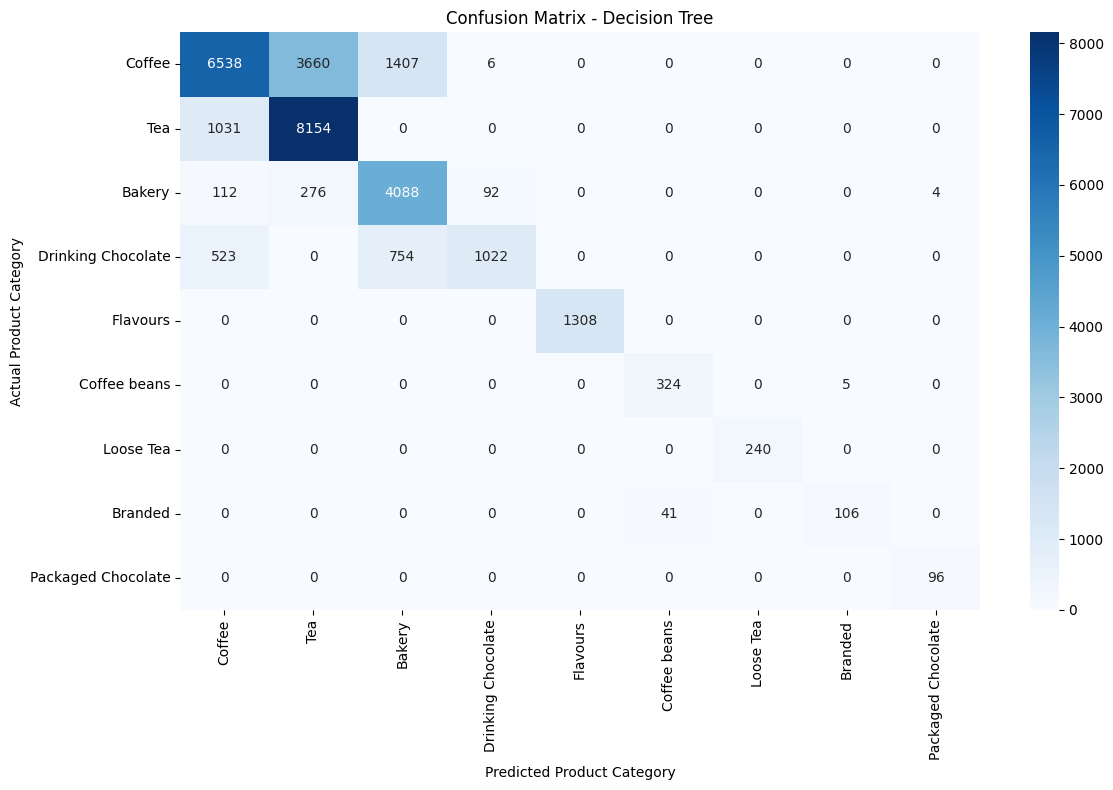

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert the confusion matrix DataFrame to Pandas
cm_pdf = confusion_df.toPandas()

# Use actual category labels
label_mapping = preprocessing_model.stages[0].labels

cm_pdf = cm_pdf.set_index("label")
cm_pdf.index = [label_mapping[int(i)] for i in cm_pdf.index]
cm_pdf.columns = [label_mapping[int(float(c))] for c in cm_pdf.columns]

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm_pdf,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Product Category")
plt.ylabel("Actual Product Category")
plt.tight_layout()
plt.show()